# Sensitivity Analysis

This is a miniature run of our experiment, including only the core data handling and our sensitivity analysis:
we will contrast how limiting the maximum value for some of our attributes influence clustering.  

In [1]:
# Necessary imports
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from datetime import datetime
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import (
apriori, association_rules)

from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

## Data importing and handling

In [2]:
columns = ['AppID', 'Name', 'Release date', 'Estimated owners', 'Peak CCU', 'Required age', 'Price', 'Discount', 'DLC count', 'About the game', 'Supported languages', 'Full audio languages', 'Reviews', 'Header image', 'Website', 'Support url', 'Support email', 'Windows', 'Mac', 'Linux', 'Metacritic score', 'Metacritic url', 'User score', 'Positive', 'Negative', 'Score rank', 'Achievements', 'Recommendations', 'Notes', 'Average playtime forever', 'Average playtime two weeks', 'Median playtime forever', 'Median playtime two weeks', 'Developers', 'Publishers', 'Categories', 'Genres', 'Tags', 'Screenshots', 'Movies']
df = pd.read_csv("games.csv",names=columns, header=0)

In [3]:
# converting release dates
df['Release date'] = pd.to_datetime(df['Release date'])
# metric to measure effort put into front page on Steam
df['Effort'] = (
    df['Screenshots'].fillna('').str.count(',') + 
    df['Screenshots'].notna().astype(int) +
    df['About the game'].fillna('').str.len() / 500
)
# Making so games with DLC count >= 1 are counted as another game
df['game_weight'] = 1 # every entry defaults to 1
df.loc[df['DLC count'] >=1, 'game_weight'] = 2 # if a game has DLC count >= 1, increase that weight to 2

# Aggregate genres across all games by developer
def aggregate_genres(genres):
    unique_genres = set()
    for game_genres in genres.dropna():
        for genre in game_genres.split(','):
            unique_genres.add(genre.strip())
    return ','.join(sorted(unique_genres))
def aggregate_genres_count(genres):
    unique_genres = set()
    for game_genres in genres.dropna():
        for genre in game_genres.split(','):
            unique_genres.add(genre.strip())
    return len(unique_genres)

# use the first release date and last release date to find how many years a developer has been active
def get_years_active(dataframe, end_year_column, start_year_column):
    years_active_list = []
    for row in dataframe.itertuples(index=True):
        index = row[0]
        start_value = start_year_column[index].year
        end_value = end_year_column[index].year
        difference = int(end_value) - int(start_value) + 1 # +1 to avoid 0, everyone has been at minimum 1 year active
        years_active_list.append(difference)
    dataframe['years_active'] = years_active_list

# group by developer and aggregate features
developers_df = df.groupby('Developers').agg(
    game_count=('game_weight', 'sum'), # how many games released, taking DLC into consideration
    total_positive=('Positive', 'sum'), # total positive reviews
    total_negative=('Negative', 'sum'), # total negative reviews
    avg_price=('Price', 'mean'), # average game price
    max_success=('Positive', 'max'), # highest success in developers career
    genres=('Genres', aggregate_genres), # all the genres a developer has used
    genre_count=('Genres', aggregate_genres_count), # count of genres per developer
    start_year=('Release date', 'min'), # year of first game released
    end_year=('Release date', 'max'), # year of last game released
    avg_effort=('Effort', 'mean') # average effort put into steam pages for games
).reset_index()

developers_df['engagement'] = developers_df['total_positive'] + developers_df['total_negative']
developers_df['avg_game_success'] =developers_df['engagement'] / developers_df['game_count']

get_years_active(developers_df, developers_df['end_year'], developers_df['start_year'])
developers_df['frequency'] = developers_df['game_count'] / developers_df['years_active']

## Sensitivity Analysis

### Without clipping

In [4]:
developers_df['game_count'].nlargest(5)

18272    232
8093     224
10780    202
32737    185
30390    165
Name: game_count, dtype: int64

In [5]:
developers_df['avg_price'].nlargest(5)

975      999.98
21311    999.00
941      500.00
1552     299.99
52306    269.99
Name: avg_price, dtype: float64

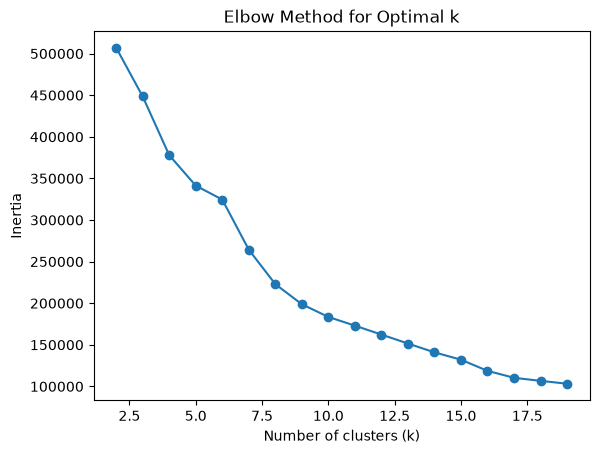

In [6]:
scaler = StandardScaler()

kmeans_df = developers_df[['game_count', 'total_positive', 'total_negative', 'avg_price', 'max_success', 'genre_count', 'avg_game_success', 'years_active','frequency']].copy()
kmeans_df_scaled_all_features = scaler.fit_transform(kmeans_df)

inertia = []
K_range = range(2, 20)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    km.fit(kmeans_df_scaled_all_features)
    inertia.append(km.inertia_)

plt.plot(K_range, inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.show()


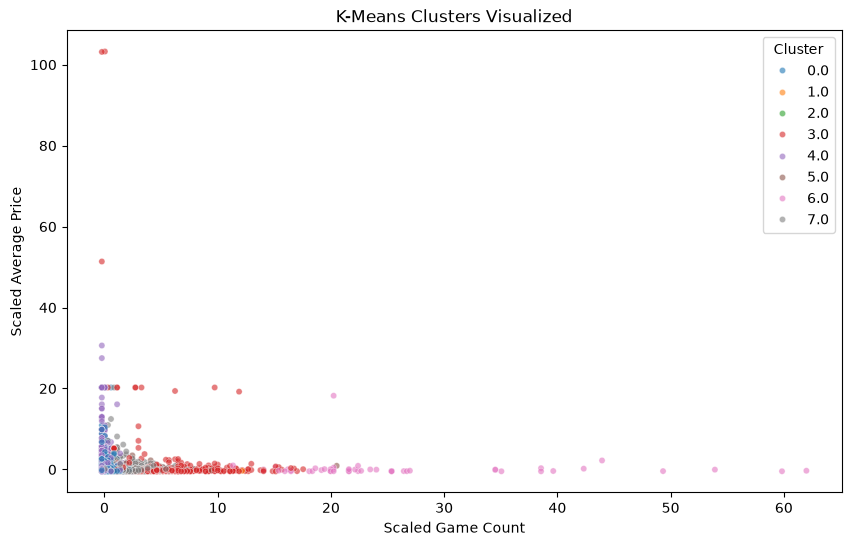

In [7]:
# initializing an instance of K-Means
kmeans = KMeans(
    n_clusters=8,
    random_state=42,
    n_init='auto'
)

# fitting the model and predicting cluster labels for each row
clusters_before = kmeans.fit_predict(kmeans_df_scaled_all_features)

# adding the cluster labels back to our developers dataframe
developers_df.loc[kmeans_df.index, 'clusters_before'] = clusters_before

# creating a temporary dataframe for plotting
plot_df = developers_df.copy()

features_for_test = ['game_count', 'avg_price']

scaler = StandardScaler()

plot_df[['scaled_game_count','scaled_avg_price']] = scaler.fit_transform(plot_df[features_for_test])

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=plot_df, 
    x='scaled_game_count', 
    y='scaled_avg_price', 
    hue='clusters_before', 
    palette='tab10', 
    alpha=0.6,
    s=20
)
plt.title('K-Means Clusters Visualized')
plt.xlabel('Scaled Game Count')
plt.ylabel('Scaled Average Price')
plt.legend(title='Cluster')
plt.show()

### With clipping

Capping game_count to a max of 10, and avg_price to a max of 100, as some outliers were heavily skewing our clusters

In [8]:
developers_df_clipped = developers_df.copy()
developers_df_clipped['game_count'] = developers_df['game_count'].clip(upper=10)
developers_df_clipped['avg_price'] = developers_df['avg_price'].clip(upper=100)

In [9]:
developers_df_clipped['game_count'].nlargest(5)

10     10
53     10
85     10
86     10
116    10
Name: game_count, dtype: int64

In [10]:
developers_df_clipped['avg_price'].nlargest(5)

511     100.0
941     100.0
975     100.0
1550    100.0
1552    100.0
Name: avg_price, dtype: float64

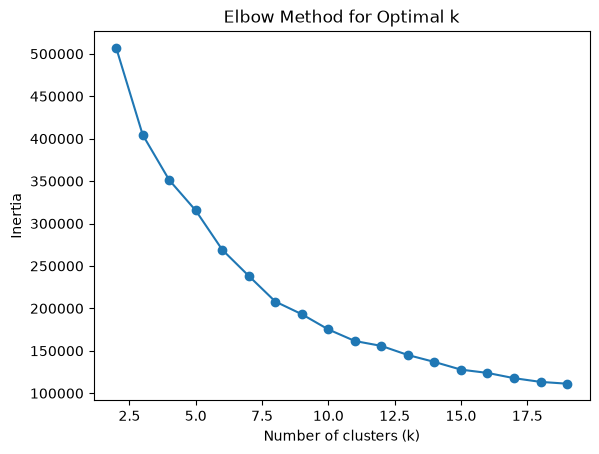

In [11]:
kmeans_df = developers_df_clipped[['game_count', 'total_positive', 'total_negative', 'avg_price', 'max_success', 'genre_count', 'avg_game_success', 'years_active','frequency']].copy()
kmeans_df_scaled_all_features = scaler.fit_transform(kmeans_df)

inertia = []
K_range = range(2, 20)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    km.fit(kmeans_df_scaled_all_features)
    inertia.append(km.inertia_)

plt.plot(K_range, inertia, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.show() # showing the elbow method again merely to contrast the difference, but we will be consistent and use the same value for K


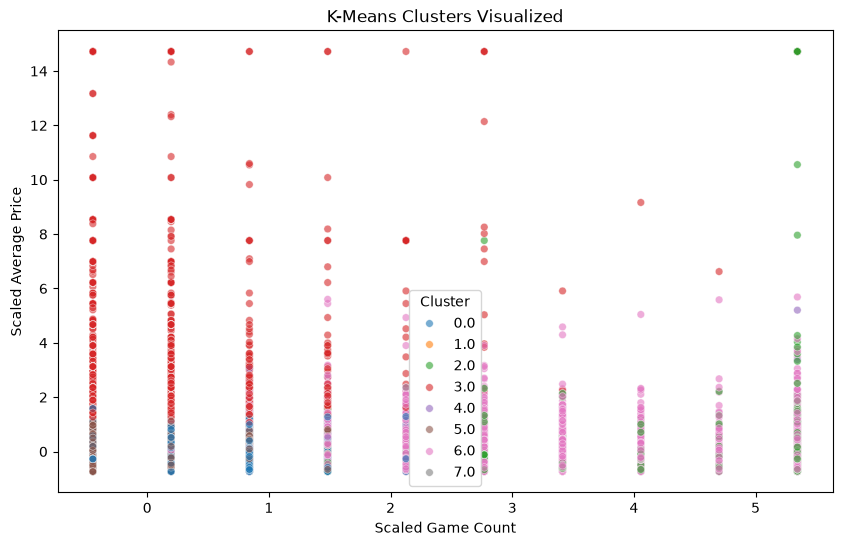

In [12]:
# using the same KMeans instance created earlier
clusters_after = kmeans.fit_predict(kmeans_df_scaled_all_features)

# adding the cluster labels back to our developers dataframe
developers_df_clipped.loc[kmeans_df.index, 'clusters_after'] = clusters_after

# creating a temporary dataframe for plotting
plot_df = developers_df_clipped.copy()

features_for_test = ['game_count', 'avg_price']

scaler = StandardScaler()

plot_df[['scaled_game_count','scaled_avg_price']] = scaler.fit_transform(plot_df[features_for_test])

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=plot_df, 
    x='scaled_game_count', 
    y='scaled_avg_price', 
    hue='clusters_after', 
    palette='tab10', 
    alpha=0.6,
    s=30
)
plt.title('K-Means Clusters Visualized')
plt.xlabel('Scaled Game Count')
plt.ylabel('Scaled Average Price')
plt.legend(title='Cluster')
plt.show()

### Comparing cluster shift

In [13]:
before = developers_df['clusters_before'].value_counts()
before

clusters_before
4.0    43324
0.0    23908
7.0     4881
3.0      645
5.0       50
6.0       49
2.0        1
1.0        1
Name: count, dtype: int64

In [14]:
after = developers_df_clipped['clusters_after'].value_counts()
after

clusters_after
5.0    39915
0.0    21657
6.0     5409
3.0     4902
2.0      938
4.0       36
7.0        1
1.0        1
Name: count, dtype: int64

In [15]:
difference = after - before
difference

clusters_after
0.0    -2251
1.0        0
2.0      937
3.0     4257
4.0   -43288
5.0    39865
6.0     5360
7.0    -4880
Name: count, dtype: int64

In [16]:
# contingency table comparing the two runs
cluster_comparison = pd.crosstab(
    developers_df['clusters_before'], 
    developers_df_clipped['clusters_after'], 
    rownames=['Before Clipping'], 
    colnames=['After Clipping']
)

cluster_comparison

After Clipping,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0
Before Clipping,,,,,,,,
0.0,21441,0,203,1608,0,0,656,0
1.0,0,1,0,0,0,0,0,0
2.0,0,0,0,0,0,0,0,1
3.0,0,0,545,26,0,0,74,0
4.0,0,0,135,3208,0,39806,175,0
5.0,3,0,0,2,36,3,6,0
6.0,0,0,48,0,0,0,1,0
7.0,213,0,7,58,0,106,4497,0
